In [9]:
from rdkit import Chem
from rdkit import RDLogger
import numpy as np
import csv
import joblib
import sys
import time
from anytree import Node, RenderTree
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
# Now you can import your module as usual
from rules import execute_step
import helper
from ml_helper import make_fingerprint

In [10]:
sm_smiles = 'CCBr.O=C1CCCC=C1.C1CN2CCN1CC2'
end_smiles = 'Br.C1CN2CCN1CC2.CCC1=CCCCC1=O'
sm = Chem.MolFromSmiles(sm_smiles)
end = Chem.MolFromSmiles(end_smiles)

sm_node = Node("SM", mol=sm)

In [11]:
# Load the model
clf = joblib.load('models/v11/xg_model.pkl')

In [21]:
force_depth = True
depth_limit = 3
step_no = 0
product_nodes = []
times_per_layer = []
nodes = [sm_node]
signal_break = False
unique_id = 0
RDLogger.DisableLog('rdApp.*') 
while step_no < depth_limit:
    start_t = time.time()
    print(f'step no {step_no}')
    nodes_to_next = []
    for int in nodes:
        try:
            product_mols, mechs, mol_inp  = execute_step("Placeholder", True, True, int.mol, False)
        except Exception as e:
            continue
        for i, product in enumerate(product_mols):
            fp = np.array(make_fingerprint(mol_inp, mechs[i]))
            # Predict using the model
            pred = clf.predict(fp.reshape(1,-1))[0]
            try:
                inchi1 = Chem.MolToInchi(product, options='/FixedH')
                inchi2 = Chem.MolToInchi(end, options='/FixedH')
            except Exception as e:
                print(f'Error processing product {i}: {e}')
                continue
            if inchi1 == inchi2:
                print('Found the target molecule!')
                print(f'The final step (mol {unique_id}) was predicted: {pred}')
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                unique_id += 1
                product_nodes.append(new_node)
                if not force_depth:
                    signal_break = True
                    break
            elif pred == 1:
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                unique_id += 1
                nodes_to_next.append(new_node)
        if signal_break:
            break
    if signal_break:
        print("we breaking")
        break
    nodes = nodes_to_next
    step_no += 1
    end_t = time.time()
    times_per_layer.append(end_t - start_t)

print("search is over")

       


step no 0
step no 1
Found the target molecule!
The final step (mol 53) was predicted: 0
Found the target molecule!
The final step (mol 54) was predicted: 1
step no 2
Found the target molecule!
The final step (mol 250) was predicted: 0
Found the target molecule!
The final step (mol 298) was predicted: 0
Found the target molecule!
The final step (mol 313) was predicted: 0
Found the target molecule!
The final step (mol 316) was predicted: 0
Found the target molecule!
The final step (mol 330) was predicted: 0
search is over


In [13]:
for i, dur in enumerate(times_per_layer):
    print(f'Layer {i+1} took {dur:.2f} seconds')

Layer 1 took 1.69 seconds
Layer 2 took 14.41 seconds
Layer 3 took 96.72 seconds


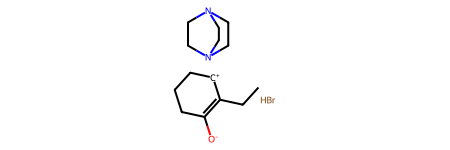

In [20]:
product_nodes[1].mol

In [27]:
def visualise_tree(node):
    mols = [node.mol]
    while node.is_root is False:
        node = node.parent
        mols.append(node.mol)
    mols.reverse()
    return Chem.Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(300, 300), legends=[f"Mol {i}" for i in range(len(mols))])

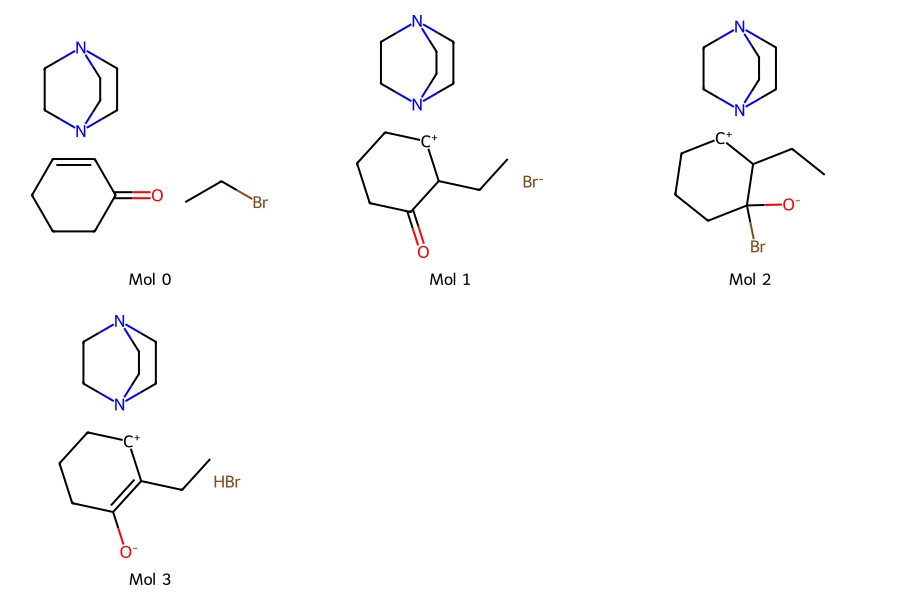

In [36]:
visualise_tree(product_nodes[5])

In [32]:
len(make_fingerprint(mol_inp, mechs[1]))

160

In [33]:
for pre, fill, node in RenderTree(sm_node):
    print(f"{pre}{node.name} - {Chem.MolToSmiles(node.mol)}")
    #if hasattr(node, 'mech'):
    #    print(f"{pre}Mechanism: {node.mech}")
    #else:
    #    print(f"{pre}Mechanism: None")

SM - C1CN2CCN1CC2.CCBr.O=C1C=CCCC1
├── Mol 0 - C1CN2CCN1CC2.CCBr.OC1=CCCC=C1
│   ├── Mol 8 - C1CN2CCN1CC2.CC[OH+]C1=CCCC=C1.[Br-]
│   ├── Mol 9 - CC[N+]12CCN(CC1)CC2.OC1=CCCC=C1.[Br-]
│   ├── Mol 10 - C1CN2CCN1CC2.CCC1[CH+]C(O)=CCC1.[Br-]
│   ├── Mol 11 - C1CN2CCN1CC2.CCC1[CH+]CCC=C1O.[Br-]
│   ├── Mol 12 - C1CN2CCN1CC2.CCC1CCC=C[C+]1O.[Br-]
│   └── Mol 13 - C1CN2CCN1CC2.CCC1(O)C=CCC[CH+]1.[Br-]
├── Mol 1 - C1C[NH+]2CCN1CC2.CCBr.[O-]C1=CCCC=C1
│   ├── Mol 14 - C1C[NH+]2CCN1CC2.C=C.OC1=CCCC=C1.[Br-]
│   ├── Mol 15 - C1CN2CCN1CC2.CCBr.OC1=CCCC=C1
│   ├── Mol 16 - C1C[NH+]2CCN1CC2.CCOC1=CCCC=C1.[Br-]
│   ├── Mol 17 - C1=CC(OCC[NH+]2CC[N-]CC2)=CCC1.CCBr
│   ├── Mol 18 - CC[N+]12CC[NH+](CC1)CC2.[Br-].[O-]C1=CCCC=C1
│   ├── Mol 19 - C1C[NH+]2CCN1CC2.CCC1[CH+]C([O-])=CCC1.[Br-]
│   ├── Mol 20 - C1C[NH+]2CCN1CC2.CCC1[CH+]CCC=C1[O-].[Br-]
│   ├── Mol 21 - C1C[NH+]2CCN1CC2.CCC1CCC=C[C+]1[O-].[Br-]
│   └── Mol 22 - C1C[NH+]2CCN1CC2.CCC1([O-])C=CCC[CH+]1.[Br-]
├── Mol 2 - C1CN2CCN1CC2.CC[O+]=C1C=C

In [20]:
new_node

Node('/SM/Mol 6/Mol 53', mech=[8, 2, 9, 4, 3], mol=<rdkit.Chem.rdchem.Mol object at 0x7f2ba3cb4740>)

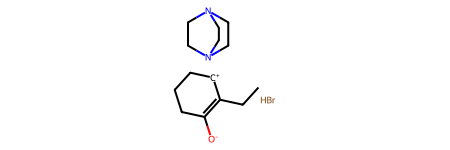

In [21]:
new_node.mol

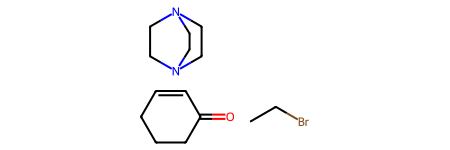

In [23]:
new_node.parent.parent.mol

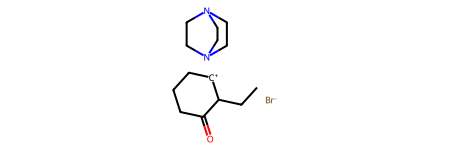

In [24]:
new_node.parent.mol